# OE2B-01 — Auditoría NU-HIVE

**Dataset:** Audio-Based Identification of Beehive States (Nolasco et al., 2019)  
**DOI:** https://doi.org/10.5281/zenodo.2667806

## Estructura del dataset

```
<RUTA_NUHIVE>/
  Hive1_12_06_2018/      ← Colmena 1, 12-jun-2018 → QR (reina presente)
  Hive1_31_05_2018/      ← Colmena 1, 31-may-2018 → QL (sin reina)
  Hive3_28_07_2017/      ← Colmena 3, 28-jul-2017 → QR (reina presente)
  Hive3_14_07_2017/      ← Colmena 3, 14-jul-2017 → QL (sin reina)
```

Nombre de archivo: `Hive1_12_06_2018_QueenBee___HH_MM_SS`  
El timestamp (HH, MM, SS) está en el nombre del archivo.  
La etiqueta QR/QL viene de la carpeta, no del archivo.

## Qué hace este notebook
1. Inventario de archivos (colmena, fecha, timestamp, estado)
2. Verificación de formato (sample rate, canales, bits, duración)
3. Cobertura horaria — ¿qué horas del día tienen grabación?
4. Verificación de consistencia — ¿los intervalos son realmente de 10 minutos?
5. Guardar inventario como CSV

**Output:** `../data/processed/nuhive/nuhive_inventario.csv`  
**No modifica ningún archivo de audio.**

## Configuración

In [1]:
from pathlib import Path

# ─── RUTA RAÍZ DE NU-HIVE ────────────────────────────────────────────────────
RUTA_NUHIVE = Path("/run/media/ikarus/KINGSTON/Tesis-Colmenas/NuHive")

# ─── RUTA DE SALIDA ──────────────────────────────────────────────────────────
RUTA_SALIDA = Path("../data/processed/nuhive/nuhive_inventario.csv")

# ─── ETIQUETAS POR CARPETA ───────────────────────────────────────────────────
# Qué estado tiene cada colmena en cada fecha de grabación
# QR = queen right (reina presente)
# QL = queenless (sin reina)
ETIQUETAS = {
    'Hive1_12_06_2018': 'QR',
    'Hive1_31_05_2018': 'QL',
    'Hive3_28_07_2017': 'QR',
    'Hive3_14_07_2017': 'QL',
}

# ─── PARÁMETROS ──────────────────────────────────────────────────────────────
# Duración esperada de cada archivo en segundos (~9 min 52 s)
DURACION_ESPERADA_SEG = 592
TOLERANCIA_SEG        = 30

# Intervalo esperado entre archivos (minutos)
INTERVALO_ESPERADO_MIN = 10
# ─────────────────────────────────────────────────────────────────────────────

RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)

print(f"Ruta NU-HIVE: {RUTA_NUHIVE}")
print(f"Existe:       {RUTA_NUHIVE.exists()}")
print()
print("Carpetas esperadas:")
for carpeta in sorted(RUTA_NUHIVE.iterdir()):
    if carpeta.is_dir():
        estado = ETIQUETAS.get(carpeta.name, '???')
        print(f"  {carpeta.name}  →  {estado}")

Ruta NU-HIVE: /run/media/ikarus/KINGSTON/Tesis-Colmenas/NuHive
Existe:       True

Carpetas esperadas:
  Hive1_12_06_2018  →  QR
  Hive1_31_05_2018  →  QL
  Hive3_14_07_2017  →  QL
  Hive3_28_07_2017  →  QR


## Importaciones

In [2]:
import pandas as pd
import numpy as np
import wave
import re
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

print("Importaciones listas")

Importaciones listas


---
## 1. Inventario de archivos

Recorremos las 4 carpetas y construimos una tabla con un archivo por fila.
- El id de colmena y la fecha salen del nombre de la carpeta (`Hive1_12_06_2018` → colmena=1, fecha=2018-06-12)
- La etiqueta QR/QL sale del diccionario `ETIQUETAS` definido en la config
- El timestamp (HH:MM:SS) sale del nombre del archivo

In [3]:
def parsear_carpeta(nombre_carpeta):
    """
    Extrae colmena_id y fecha del nombre de la carpeta.
    Ejemplo: 'Hive1_12_06_2018' → (1, date(2018, 6, 12))
    """
    # Formato: Hive{N}_{DD}_{MM}_{YYYY}
    m = re.match(r'Hive(\d+)_(\d{2})_(\d{2})_(\d{4})$', nombre_carpeta)
    if not m:
        return None, None
    colmena_id = int(m.group(1))
    fecha = pd.to_datetime(f"{m.group(4)}-{m.group(3)}-{m.group(2)}").date()
    return colmena_id, fecha


def parsear_timestamp(nombre_archivo, fecha):
    """
    Extrae el timestamp completo del nombre del archivo.
    Ejemplo: 'Hive1_12_06_2018_QueenBee___23_50_00' → datetime(2018, 6, 12, 23, 50, 0)
    El nombre puede no tener extensión visible.
    """
    stem = Path(nombre_archivo).stem
    # Buscar HH_MM_SS al final del nombre (pueden haber espacios/guiones bajos antes)
    m = re.search(r'(\d{2})_(\d{2})_(\d{2})$', stem)
    if m:
        h, mi, s = int(m.group(1)), int(m.group(2)), int(m.group(3))
        return pd.Timestamp(year=fecha.year, month=fecha.month, day=fecha.day,
                            hour=h, minute=mi, second=s)
    return pd.NaT


registros = []

for carpeta in sorted(RUTA_NUHIVE.iterdir()):
    if not carpeta.is_dir():
        continue

    colmena_id, fecha = parsear_carpeta(carpeta.name)
    if colmena_id is None:
        print(f"⚠️  No se pudo parsear carpeta: {carpeta.name}")
        continue

    estado = ETIQUETAS.get(carpeta.name, None)
    if estado is None:
        print(f"⚠️  Sin etiqueta para: {carpeta.name}")
        continue

    # Buscar archivos de audio (wav o sin extensión)
    archivos = sorted(list(carpeta.glob('*.wav')) + list(carpeta.glob('*.WAV')))
    if not archivos:
        # Algunos datasets no tienen extensión
        archivos = [f for f in sorted(carpeta.iterdir()) if f.is_file()]

    for archivo in archivos:
        ts = parsear_timestamp(archivo.name, fecha)
        registros.append({
            'colmena_id':  colmena_id,
            'fecha':       fecha,
            'estado':      estado,
            'timestamp':   ts,
            'nombre':      archivo.name,
            'ruta':        str(archivo),
            'tamanio_mb':  archivo.stat().st_size / (1024 * 1024),
        })

df_inv = pd.DataFrame(registros)

print(f"Archivos encontrados: {len(df_inv):,}")
print()
print("Por carpeta (colmena + estado):")
print(df_inv.groupby(['colmena_id', 'fecha', 'estado']).size()
      .rename('n_archivos').to_string())
print()
print("Muestra:")
df_inv.head()

Archivos encontrados: 576

Por carpeta (colmena + estado):
colmena_id  fecha       estado
1           2018-05-31  QL        144
            2018-06-12  QR        144
3           2017-07-14  QL        144
            2017-07-28  QR        144

Muestra:


,colmena_id,fecha,estado,timestamp,nombre,ruta,tamanio_mb
0,1,2018-06-12,QR,2018-06-12 00:00:00,Hive1 12_06_2018_QueenBee____00_00_00.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/NuHi...,72.265667
1,1,2018-06-12,QR,2018-06-12 00:10:00,Hive1 12_06_2018_QueenBee____00_10_00.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/NuHi...,72.265667
2,1,2018-06-12,QR,2018-06-12 00:20:00,Hive1 12_06_2018_QueenBee____00_20_00.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/NuHi...,72.656292
3,1,2018-06-12,QR,2018-06-12 00:30:00,Hive1 12_06_2018_QueenBee____00_30_00.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/NuHi...,73.046917
4,1,2018-06-12,QR,2018-06-12 00:40:00,Hive1 12_06_2018_QueenBee____00_40_00.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/NuHi...,72.656292


---
## 2. Verificar timestamps

Chequeamos cuántos archivos se parsearon correctamente y vemos si hay huecos en la secuencia horaria.

In [4]:
n_sin_ts = df_inv['timestamp'].isna().sum()
print(f"Timestamps parseados: {len(df_inv) - n_sin_ts:,} de {len(df_inv):,}")
if n_sin_ts > 0:
    print(f"⚠️  {n_sin_ts} archivos sin timestamp")
    print(df_inv[df_inv['timestamp'].isna()]['nombre'].head(5).to_string())

print()
print("Rango horario por carpeta:")
for (col_id, fecha, estado), grupo in df_inv.groupby(['colmena_id', 'fecha', 'estado']):
    ts_ok = grupo['timestamp'].dropna().sort_values()
    print(f"  Hive{col_id} {fecha} ({estado}):  "
          f"{ts_ok.iloc[0].strftime('%H:%M')} → {ts_ok.iloc[-1].strftime('%H:%M')}  "
          f"({len(ts_ok)} archivos)")

Timestamps parseados: 576 de 576

Rango horario por carpeta:
  Hive1 2018-05-31 (QL):  00:00 → 23:50  (144 archivos)
  Hive1 2018-06-12 (QR):  00:00 → 23:50  (144 archivos)
  Hive3 2017-07-14 (QL):  00:00 → 23:50  (144 archivos)
  Hive3 2017-07-28 (QR):  00:00 → 23:50  (144 archivos)


---
## 3. Verificar intervalos entre archivos

Confirmamos que el intervalo entre grabaciones es consistentemente de 10 minutos.
Los intervalos anómalos (gaps) indican que falta algún archivo.

In [5]:
print(f"Intervalo esperado: {INTERVALO_ESPERADO_MIN} minutos")
print()

todos_intervalos = []

for (col_id, fecha, estado), grupo in df_inv.groupby(['colmena_id', 'fecha', 'estado']):
    ts = grupo['timestamp'].dropna().sort_values()
    if len(ts) < 2:
        continue

    # Calcular diferencias en minutos entre archivos consecutivos
    diffs_min = ts.diff().dropna().dt.total_seconds() / 60

    intervalos_anomalos = diffs_min[diffs_min != INTERVALO_ESPERADO_MIN]

    print(f"  Hive{col_id} {fecha} ({estado}):")
    print(f"    Intervalo más común: {diffs_min.mode().iloc[0]:.0f} min")
    print(f"    Intervalos distintos de {INTERVALO_ESPERADO_MIN} min: {len(intervalos_anomalos)}")
    if len(intervalos_anomalos) > 0:
        for idx, val in intervalos_anomalos.items():
            print(f"      → {val:.0f} min en {ts[idx].strftime('%H:%M')}")
    print()

    todos_intervalos.extend(diffs_min.tolist())

print("Distribución global de intervalos (minutos):")
print(pd.Series(todos_intervalos).value_counts().sort_index().to_string())

Intervalo esperado: 10 minutos

  Hive1 2018-05-31 (QL):
    Intervalo más común: 10 min
    Intervalos distintos de 10 min: 0

  Hive1 2018-06-12 (QR):
    Intervalo más común: 10 min
    Intervalos distintos de 10 min: 0

  Hive3 2017-07-14 (QL):
    Intervalo más común: 10 min
    Intervalos distintos de 10 min: 0

  Hive3 2017-07-28 (QR):
    Intervalo más común: 10 min
    Intervalos distintos de 10 min: 0

Distribución global de intervalos (minutos):
10.0    572


---
## 4. Verificar formato de audio

Leemos el header WAV de todos los archivos para confirmar sample rate, canales, bits y duración.
Estos valores son críticos para el preprocesamiento (hay que resamplear a 8 kHz si es necesario).

In [6]:
print(f"Leyendo headers de {len(df_inv):,} archivos...")

sample_rates = []
canales_list = []
bits_list    = []
duraciones   = []
n_error      = 0

for _, fila in df_inv.iterrows():
    try:
        with wave.open(fila['ruta'], 'rb') as wf:
            sr  = wf.getframerate()
            ch  = wf.getnchannels()
            bit = wf.getsampwidth() * 8
            dur = wf.getnframes() / sr
    except Exception as e:
        sr = ch = bit = dur = None
        n_error += 1

    sample_rates.append(sr)
    canales_list.append(ch)
    bits_list.append(bit)
    duraciones.append(dur)

df_inv['sample_rate']  = sample_rates
df_inv['canales']      = canales_list
df_inv['bits']         = bits_list
df_inv['duracion_seg'] = duraciones

if n_error > 0:
    print(f"⚠️  {n_error} archivos no se pudieron leer")

print()
print("Sample rate (Hz):")
print(df_inv['sample_rate'].value_counts().to_string())
print()
print("Canales:")
print(df_inv['canales'].value_counts().to_string())
print()
print("Bits por muestra:")
print(df_inv['bits'].value_counts().to_string())
print()
print("Duración (seg) — estadísticas:")
print(df_inv['duracion_seg'].describe().round(1).to_string())
print()

# Marcar archivos anómalos por duración
lim_min = DURACION_ESPERADA_SEG - TOLERANCIA_SEG
lim_max = DURACION_ESPERADA_SEG + TOLERANCIA_SEG
df_inv['duracion_anomala'] = (
    df_inv['duracion_seg'].isna() |
    (df_inv['duracion_seg'] < lim_min) |
    (df_inv['duracion_seg'] > lim_max)
)
print(f"Archivos con duración anómala (fuera de {lim_min}s–{lim_max}s): "
      f"{df_inv['duracion_anomala'].sum()}")

Leyendo headers de 576 archivos...

Sample rate (Hz):
sample_rate
32000    288
44100    288

Canales:
canales
2    576

Bits por muestra:
bits
16    576

Duración (seg) — estadísticas:
count    576.0
mean     588.2
std       28.7
min       85.9
25%      585.1
50%      592.0
75%      598.4
max      601.6

Archivos con duración anómala (fuera de 562s–622s): 8


---
## 5. Cobertura horaria

¿A qué horas del día hay grabaciones? Esto es importante para entender si el dataset cubre
las 24 horas o solo parte del día, y si las 4 carpetas tienen cobertura similar.

In [7]:
df_inv['hora'] = df_inv['timestamp'].dt.hour

print("Archivos por hora (todas las carpetas):")
print(df_inv.groupby('hora').size().to_string())
print()
print("Cobertura horaria por carpeta:")
pivot = df_inv.groupby(['colmena_id', 'estado', 'hora']).size().unstack(fill_value=0)
print(pivot.to_string())

Archivos por hora (todas las carpetas):
hora
0     24
1     24
2     24
3     24
4     24
5     24
6     24
7     24
8     24
9     24
10    24
11    24
12    24
13    24
14    24
15    24
16    24
17    24
18    24
19    24
20    24
21    24
22    24
23    24

Cobertura horaria por carpeta:
hora               0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
colmena_id estado                                                                                                
1          QL       6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6
           QR       6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6
3          QL       6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6
           QR       6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6   6


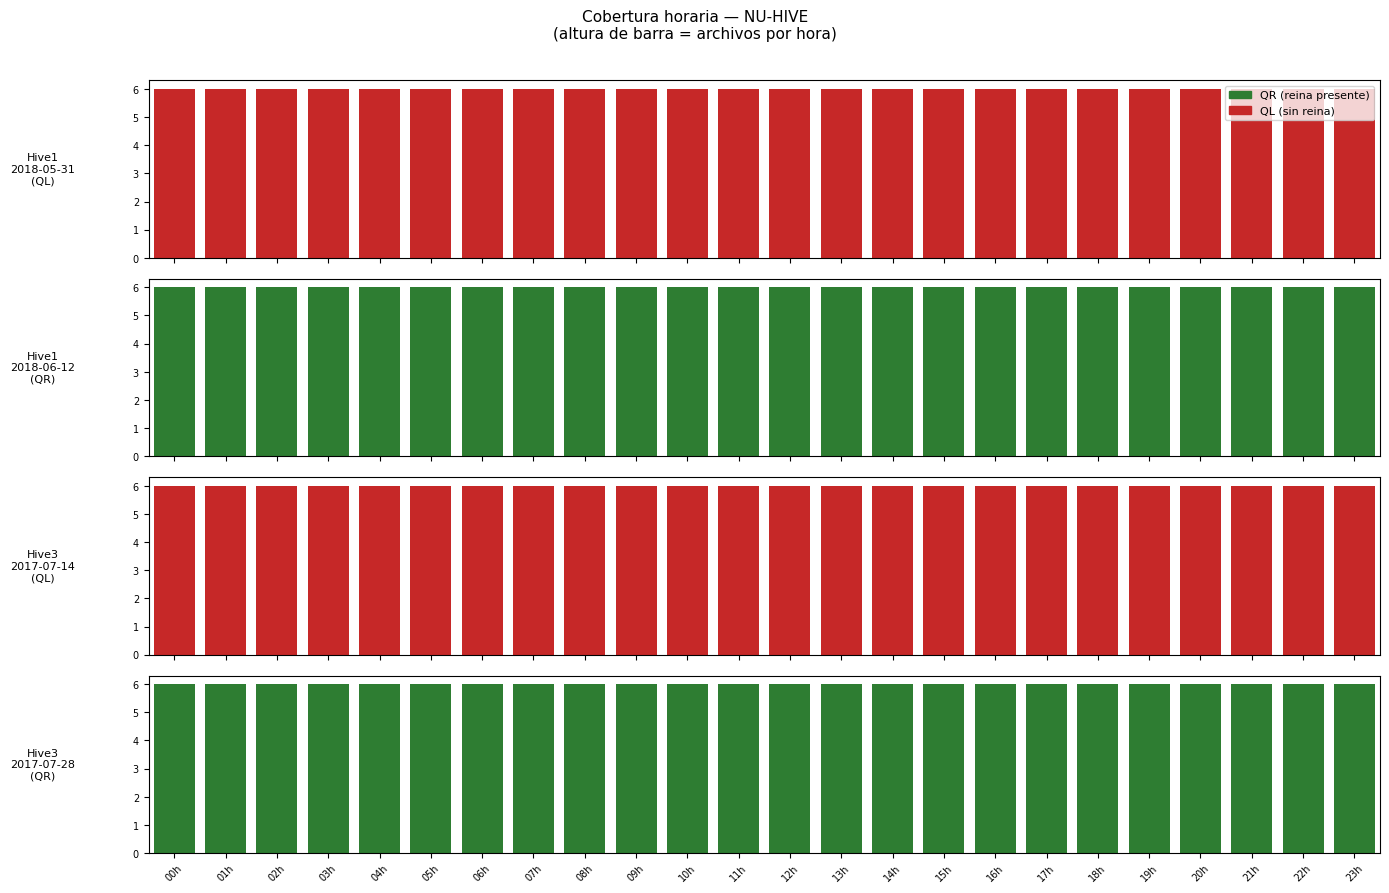

In [8]:
# Gráfico: cobertura horaria — un panel por carpeta
grupos = list(df_inv.groupby(['colmena_id', 'fecha', 'estado']))
n_grupos = len(grupos)

fig, axes = plt.subplots(n_grupos, 1, figsize=(14, n_grupos * 2.2), sharex=True)
if n_grupos == 1:
    axes = [axes]

horas_completas = list(range(24))

for ax, ((col_id, fecha, estado), grupo) in zip(axes, grupos):
    conteo_hora = grupo.groupby('hora').size().reindex(horas_completas, fill_value=0)
    color = '#2E7D32' if estado == 'QR' else '#C62828'
    ax.bar(horas_completas, conteo_hora.values, color=color, width=0.8, linewidth=0)
    ax.set_ylabel(f"Hive{col_id}\n{fecha}\n({estado})",
                  fontsize=8, rotation=0, labelpad=65, va='center')
    ax.tick_params(axis='y', labelsize=7)
    ax.set_xlim(-0.5, 23.5)

axes[-1].set_xticks(range(24))
axes[-1].set_xticklabels([f"{h:02d}h" for h in range(24)], fontsize=7, rotation=45)

leyenda = [
    Patch(color='#2E7D32', label='QR (reina presente)'),
    Patch(color='#C62828', label='QL (sin reina)'),
]
axes[0].legend(handles=leyenda, loc='upper right', fontsize=8)

fig.suptitle("Cobertura horaria — NU-HIVE\n(altura de barra = archivos por hora)",
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

---
## 6. Plan de preprocesamiento para xnorC

Con base en los resultados de la auditoría, definimos los pasos de preprocesamiento
necesarios antes de poder usar NU-HIVE en el pipeline de xnorC.

In [9]:
# Resumen del plan de preprocesamiento
# (se ejecuta en OE2B-04 junto con Yang)

sr_encontrado = df_inv['sample_rate'].mode().iloc[0] if df_inv['sample_rate'].notna().any() else 'desconocido'
canales_encontrado = df_inv['canales'].mode().iloc[0] if df_inv['canales'].notna().any() else 'desconocido'

print("Plan de preprocesamiento — NU-HIVE:")
print()
print(f"  Sample rate actual:    {sr_encontrado} Hz")
print(f"  Sample rate objetivo:  8.000 Hz")
if sr_encontrado != 8000:
    print(f"  → Necesita resampleo: SÍ")
else:
    print(f"  → Necesita resampleo: NO")
print()
print(f"  Canales actual:        {canales_encontrado}")
if canales_encontrado != 1:
    print(f"  → Necesita conversión a mono: SÍ")
else:
    print(f"  → Necesita conversión a mono: NO")
print()
print("  Normalización de amplitud: SÍ (a rango [-1, +1])")
print()
print("  Segmentación para xnorC:")
dur_media = df_inv['duracion_seg'].median()
print(f"    Duración mediana del archivo: {dur_media:.0f}s (~{dur_media/60:.1f} min)")
print(f"    Ventana B1/B2/B3/B4: 2 segundos → {int(dur_media // 2)} segmentos por archivo")
print()
print("  Agregación a 1 hora:")
print("    Cada hora contiene ~6 archivos × ~6 min útiles = ~36 min de audio por hora")
print("    Se promediará a nivel de features (no de audio crudo)")

Plan de preprocesamiento — NU-HIVE:

  Sample rate actual:    32000 Hz
  Sample rate objetivo:  8.000 Hz
  → Necesita resampleo: SÍ

  Canales actual:        2
  → Necesita conversión a mono: SÍ

  Normalización de amplitud: SÍ (a rango [-1, +1])

  Segmentación para xnorC:
    Duración mediana del archivo: 592s (~9.9 min)
    Ventana B1/B2/B3/B4: 2 segundos → 296 segmentos por archivo

  Agregación a 1 hora:
    Cada hora contiene ~6 archivos × ~6 min útiles = ~36 min de audio por hora
    Se promediará a nivel de features (no de audio crudo)


---
## 7. Guardar inventario

In [10]:
ORDEN_COLUMNAS = ['colmena_id', 'fecha', 'estado', 'timestamp', 'hora',
                   'nombre', 'ruta', 'tamanio_mb',
                   'sample_rate', 'canales', 'bits', 'duracion_seg', 'duracion_anomala']

cols_finales = [c for c in ORDEN_COLUMNAS if c in df_inv.columns]
df_inv[cols_finales].to_csv(RUTA_SALIDA, index=False)

print(f"Inventario guardado en: {RUTA_SALIDA}")
print()
print("=" * 50)
print("RESUMEN FINAL — NU-HIVE")
print("=" * 50)
print(f"  Archivos totales:       {len(df_inv):,}")
print(f"  Colmenas:               {df_inv['colmena_id'].nunique()}  (Hive1, Hive3)")
print(f"  Días de grabación:      {df_inv['fecha'].nunique()}")
print(f"  Archivos QR:            {(df_inv['estado']=='QR').sum():,}")
print(f"  Archivos QL:            {(df_inv['estado']=='QL').sum():,}")
print(f"  Archivos anómalos:      {df_inv['duracion_anomala'].sum()}")
dur_total_h = df_inv['duracion_seg'].sum() / 3600
print(f"  Duración total:         {dur_total_h:.1f} horas")
print(f"  Sample rate:            {df_inv['sample_rate'].mode().iloc[0]:,} Hz")
print(f"  Canales:                {df_inv['canales'].mode().iloc[0]}")
print()
print("─── Próximo paso ───")
print("  OE2B-02: Auditoría Yang (confirmación de formato para xnorC)")

Inventario guardado en: ../data/processed/nuhive/nuhive_inventario.csv

RESUMEN FINAL — NU-HIVE
  Archivos totales:       576
  Colmenas:               2  (Hive1, Hive3)
  Días de grabación:      4
  Archivos QR:            288
  Archivos QL:            288
  Archivos anómalos:      8
  Duración total:         94.1 horas
  Sample rate:            32,000 Hz
  Canales:                2

─── Próximo paso ───
  OE2B-02: Auditoría Yang (confirmación de formato para xnorC)
